In [1]:

import pandas as pd
import numpy as np

# 1. Read the original ChEMBL dataset
df = pd.read_csv("PPI_IC50_raw.csv")

# 2. Keep exact, positive IC50 measurements in nM
df = df[
    (df["standard_type"] == "IC50")
    & (df["standard_units"] == "nM")
    & (df["standard_relation"] == "=")
    & (df["standard_value"] > 0)
    & df["canonical_smiles"].notna()
    & df["molecule_chembl_id"].notna()
].copy()

# 3. Convert IC50 (nM) to pIC50
df["pIC50"] = 9 - np.log10(df["standard_value"])

# 4. Save all individual measurements
df.to_csv("PPI_records_with_pIC50_309.csv", index=False)

# 5. Group repeated measurements by molecule
summary = df.groupby("molecule_chembl_id", as_index=False).agg(
    canonical_smiles=("canonical_smiles", "first"),
    pIC50_median=("pIC50", "median"),
    pIC50_min=("pIC50", "min"),
    pIC50_max=("pIC50", "max"),
    n_measurements=("pIC50", "size"),
    n_assays=("assay_chembl_id", "nunique"),
    IC50_nM_median=("standard_value", "median")
)

# 6. Calculate measurement variability
summary["pIC50_range"] = (
    summary["pIC50_max"] - summary["pIC50_min"]
)

# 7. Save molecule-level summary
summary.to_csv("PPI_molecule_summary_248.csv", index=False)

# 8. Print dataset information
print("Total records:", len(df))
print("Unique molecules:", len(summary))
print("Distinct assays:", df["assay_chembl_id"].nunique())
print("pIC50 range:", df["pIC50"].min(), df["pIC50"].max())


Total records: 309
Unique molecules: 248
Distinct assays: 11
pIC50 range: 3.3545777306509077 7.698970004336019


In [2]:
from chembl_webresource_client.new_client import new_client
import pandas as pd

target_id = "CHEMBL2095173"

activities = new_client.activity.filter(
    target_chembl_id=target_id
).only(
    "molecule_chembl_id",
    "canonical_smiles",
    "assay_chembl_id",
    "assay_type",
    "standard_type",
    "standard_value",
    "standard_units",
    "standard_relation",
    "pchembl_value",
    "data_validity_comment",
    "assay_description"
)

df_all = pd.DataFrame(list(activities))

print("Total activity records:", len(df_all))
print("Unique molecules:",
      df_all["molecule_chembl_id"].nunique())

print("\nAssay types:")
print(df_all["assay_type"].value_counts(dropna=False))

print("\nActivity types:")
print(df_all["standard_type"].value_counts(dropna=False))

print("\nAssay type vs activity type:")
display(pd.crosstab(
    df_all["assay_type"],
    df_all["standard_type"]
))

df_all.to_csv("PPI_all_activities_raw.csv", index=False)

Total activity records: 493
Unique molecules: 336

Assay types:
assay_type
B    351
F    142
Name: count, dtype: int64

Activity types:
standard_type
IC50          327
Inhibition    166
Name: count, dtype: int64

Assay type vs activity type:


standard_type,IC50,Inhibition
assay_type,,
B,203,148
F,124,18


In [3]:
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors

df = pd.read_csv("PPI_molecule_summary_248.csv")

def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return pd.Series({
            "MW": np.nan,
            "LogP": np.nan,
            "TPSA": np.nan,
            "HBD": np.nan,
            "HBA": np.nan,
            "RotatableBonds": np.nan
        })

    return pd.Series({
        "MW": Descriptors.MolWt(mol),
        "LogP": Crippen.MolLogP(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": rdMolDescriptors.CalcNumHBD(mol),
        "HBA": rdMolDescriptors.CalcNumHBA(mol),
        "RotatableBonds":
            rdMolDescriptors.CalcNumRotatableBonds(mol)
    })

descriptors = df["canonical_smiles"].apply(
    calculate_descriptors
)

df = pd.concat([df, descriptors], axis=1)

display(df.head())

df.to_csv("PPI_descriptors.csv", index=False)

,molecule_chembl_id,canonical_smiles,pIC50_median,pIC50_min,pIC50_max,n_measurements,n_assays,IC50_nM_median,pIC50_range,MW,LogP,TPSA,HBD,HBA,RotatableBonds
0,CHEMBL10060,COc1ccnc(C[S+]([O-])c2nc3cc(OC(F)F)ccc3[nH]2)c1,5.800001,5.800001,5.800001,1,1,1584.89,0.0,353.350,2.87570,83.09,1.0,5.0,6.0
1,CHEMBL10061,COc1cnc(C[S+]([O-])c2nc3cc(OC(F)(F)C(F)F)ccc3[...,5.100000,5.100000,5.100000,1,1,7943.28,0.0,447.410,3.82802,92.32,1.0,6.0,8.0
2,CHEMBL10070,COc1cnc(C[S+]([O-])c2nc3cc(OC(F)(F)C(F)F)ccc3[...,4.700000,4.700000,4.700000,1,1,19952.62,0.0,433.383,3.51960,92.32,1.0,6.0,8.0
3,CHEMBL10075,COc1cc(C[S+]([O-])c2nc3cc(OC(F)(F)C(F)F)ccc3[n...,5.899998,5.899998,5.899998,1,1,1258.93,0.0,417.384,3.81942,83.09,1.0,5.0,7.0
4,CHEMBL108285,COc1cc(OC)c(C[S+]([O-])c2ncccc2C(=O)Nc2ccncc2)...,5.920819,5.920819,5.920819,1,1,1200.00,0.0,427.482,3.06250,105.63,1.0,7.0,8.0


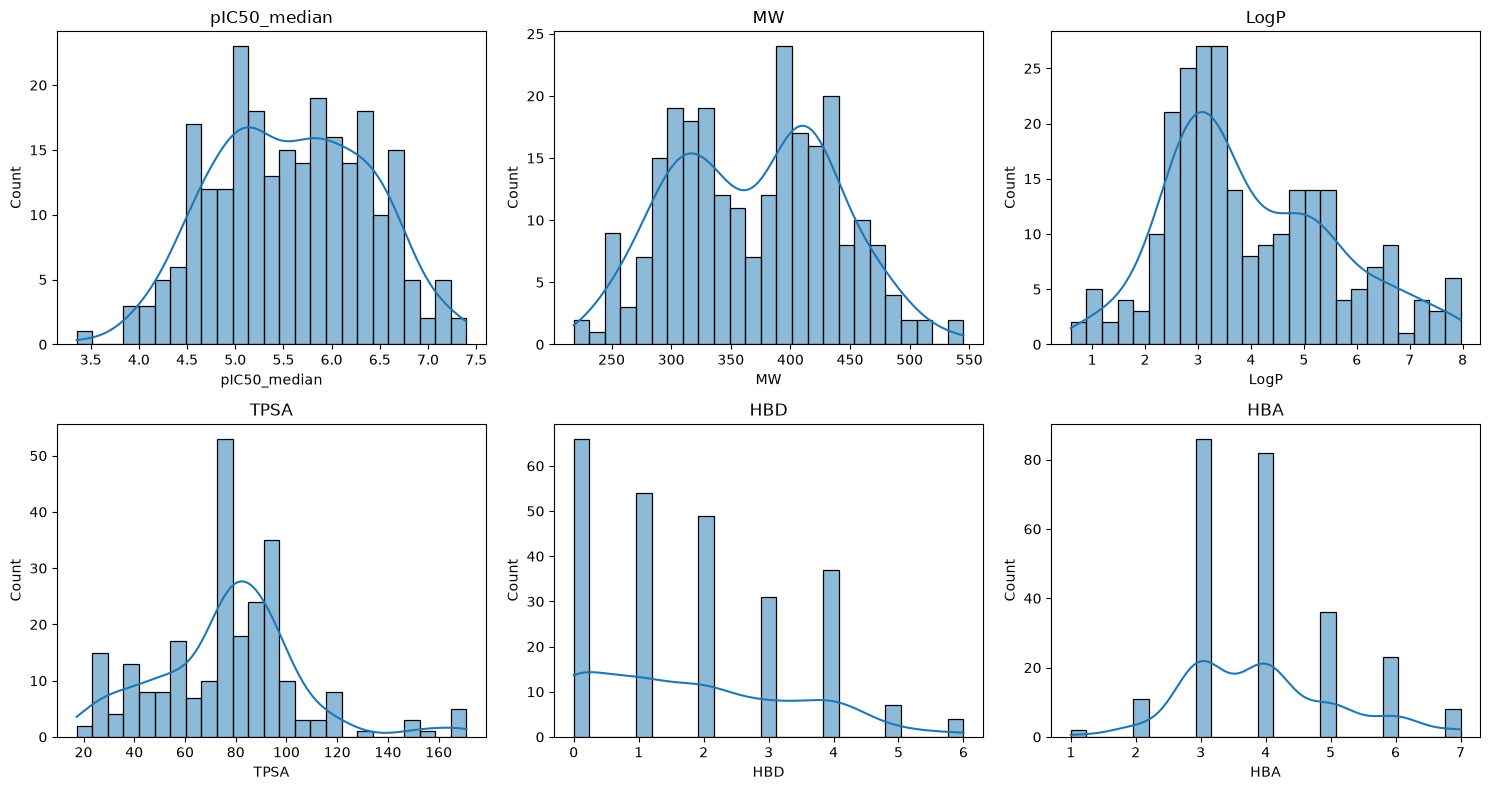

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = [
    "pIC50_median",
    "MW",
    "LogP",
    "TPSA",
    "HBD",
    "HBA"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), columns):
    sns.histplot(
        df[col].dropna(),
        bins=25,
        kde=True,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

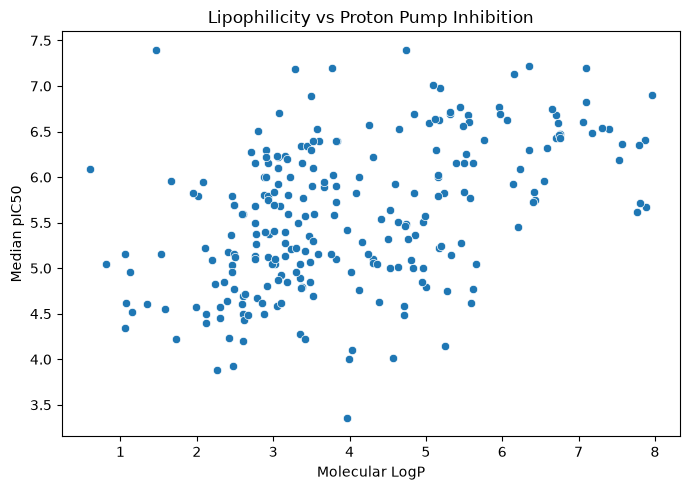

In [5]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="LogP",
    y="pIC50_median"
)

plt.xlabel("Molecular LogP")
plt.ylabel("Median pIC50")
plt.title("Lipophilicity vs Proton Pump Inhibition")

plt.tight_layout()
plt.show()

In [6]:

import numpy as np
import pandas as pd

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold

from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("PPI_descriptors.csv")

descriptor_cols = [
    "MW", "LogP", "TPSA",
    "HBD", "HBA", "RotatableBonds"
]

X_desc = df[descriptor_cols].to_numpy()
y = df["pIC50_median"].to_numpy()

# Morgan fingerprint: radius 2, 2048 bits
fpgen = rdFingerprintGenerator.GetMorganGenerator(
    radius=2, fpSize=2048
)

fingerprints = []
scaffolds = []

for smiles in df["canonical_smiles"]:
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Invalid SMILES: {smiles}")

    fp = fpgen.GetFingerprint(mol)
    arr = np.zeros(2048, dtype=np.int8)
    DataStructs.ConvertToNumpyArray(fp, arr)
    fingerprints.append(arr)

    scaffolds.append(
        MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
    )

X_fp = np.asarray(fingerprints)

print("Descriptor matrix:", X_desc.shape)
print("Fingerprint matrix:", X_fp.shape)
print("Unique scaffolds:", len(set(scaffolds)))


Descriptor matrix: (248, 6)
Fingerprint matrix: (248, 2048)
Unique scaffolds: 61


In [7]:

results = []
predictions = {}

# Random molecule split
idx = np.arange(len(df))

random_train, random_test = train_test_split(
    idx, test_size=0.2, random_state=42
)

# Scaffold-based split: scaffold groups do not overlap
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

scaffold_train, scaffold_test = next(
    splitter.split(X_desc, y, groups=scaffolds)
)

splits = {
    "Random": (random_train, random_test),
    "Scaffold": (scaffold_train, scaffold_test)
}

feature_sets = {
    "Descriptors": X_desc,
    "Morgan FP": X_fp
}

for split_name, (train_idx, test_idx) in splits.items():

    for feature_name, X in feature_sets.items():

        model = RandomForestRegressor(
            n_estimators=500,
            random_state=42,
            n_jobs=-1,
            min_samples_leaf=2
        )

        model.fit(X[train_idx], y[train_idx])
        y_pred = model.predict(X[test_idx])

        results.append({
            "Split": split_name,
            "Features": feature_name,
            "MAE": mean_absolute_error(
                y[test_idx], y_pred
            ),
            "RMSE": np.sqrt(mean_squared_error(
                y[test_idx], y_pred
            )),
            "R2": r2_score(y[test_idx], y_pred)
        })

        predictions[(split_name, feature_name)] = (
            y[test_idx], y_pred
        )

    # Mean-prediction baseline
    dummy = DummyRegressor(strategy="mean")
    dummy.fit(X_desc[train_idx], y[train_idx])
    y_dummy = dummy.predict(X_desc[test_idx])

    results.append({
        "Split": split_name,
        "Features": "Mean baseline",
        "MAE": mean_absolute_error(
            y[test_idx], y_dummy
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y[test_idx], y_dummy
        )),
        "R2": r2_score(y[test_idx], y_dummy)
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))


,Split,Features,MAE,RMSE,R2
0,Random,Descriptors,0.445,0.565,0.519
1,Random,Morgan FP,0.389,0.505,0.615
2,Random,Mean baseline,0.684,0.814,-0.001
3,Scaffold,Descriptors,0.594,0.805,0.304
4,Scaffold,Morgan FP,0.544,0.765,0.372
5,Scaffold,Mean baseline,0.884,1.012,-0.098


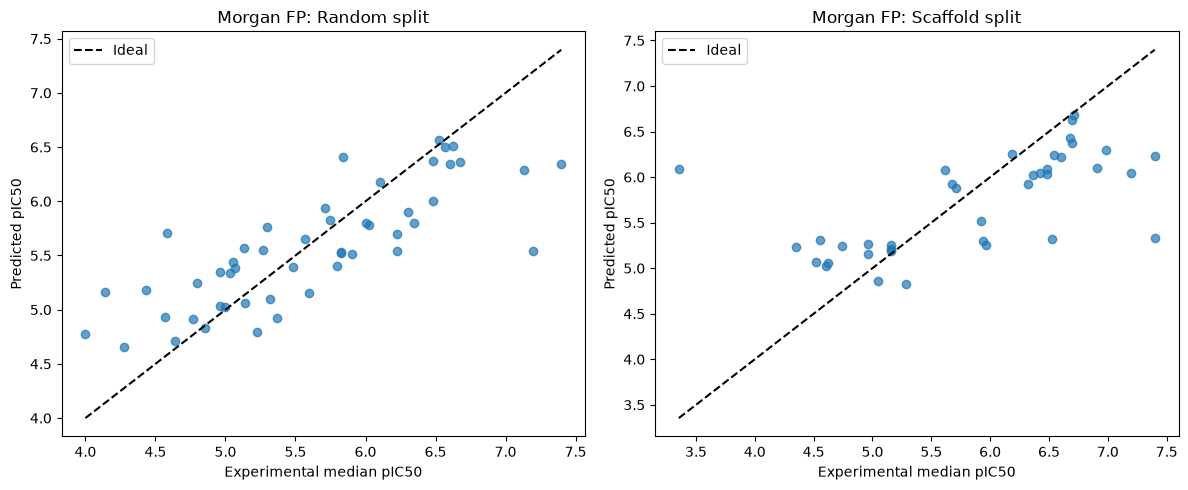

In [8]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, split_name in zip(
    axes, ["Random", "Scaffold"]
):
    y_true, y_pred = predictions[
        (split_name, "Morgan FP")
    ]

    ax.scatter(y_true, y_pred, alpha=0.7)

    limits = [
        min(y_true.min(), y_pred.min()),
        max(y_true.max(), y_pred.max())
    ]

    ax.plot(limits, limits, "k--", label="Ideal")
    ax.set_xlabel("Experimental median pIC50")
    ax.set_ylabel("Predicted pIC50")
    ax.set_title(f"Morgan FP: {split_name} split")
    ax.legend()

plt.tight_layout()
plt.show()

results_df.to_csv("PPI_RF_baseline_results.csv", index=False)
